In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

In [47]:
df = pd.read_parquet("../DATASETS/processed/dataset_maestro_permanencia.parquet")
df.head()

,CAT_PERIODO,CODIGO_UNICO,MRUN,GEN_ALU,TIPO_INST_1,TIPO_INST_3,MODALIDAD,JORNADA,DUR_TOTAL_CARR,REGION_SEDE,...,EDAD,DECIL_SE4,COD_DEPE,NEM,NACIONALIDAD,ETNIA,PERMANECE_CARRERA,PERMANECE_SISTEMA,ES_EXTRANJERO,ANIO_COHORTE
0,2022,I45S2C4J1V1,26,2,Universidades,Universidades Privadas,Presencial,Diurna,12,Metropolitana,...,19,9.0,3.0,595.0,0,1,1,1,0,2022
1,2022,I143S27C34J2V1,51,2,Institutos Profesionales,Institutos Profesionales,Presencial,Vespertina,5,Metropolitana,...,39,5.0,2.0,560.0,0,1,1,1,0,2022
2,2022,I895S1C3J1V1,163,2,Universidades,Universidades Estatales CRUCH,Presencial,Diurna,14,Lib. Gral. B. O'Higgins,...,18,9.0,4.0,685.0,0,1,1,1,0,2022
3,2022,I71S1C68J1V1,164,2,Universidades,Universidades Estatales CRUCH,Presencial,Diurna,10,Metropolitana,...,18,9.0,4.0,647.0,0,1,1,1,0,2022
4,2022,I430S23C78J1V1,192,1,Centros de Formación Técnica,Centros de Formación Técnica Privados,Presencial,Diurna,5,Los Lagos,...,24,8.0,1.0,530.0,0,7,1,1,0,2022


C:\Users\Thinkpad\AppData\Local\Temp\ipykernel_4784\1890999815.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=sin_nem, x="GRUPO_NAC", y="NEM", ax=axes[0], palette="Set2")


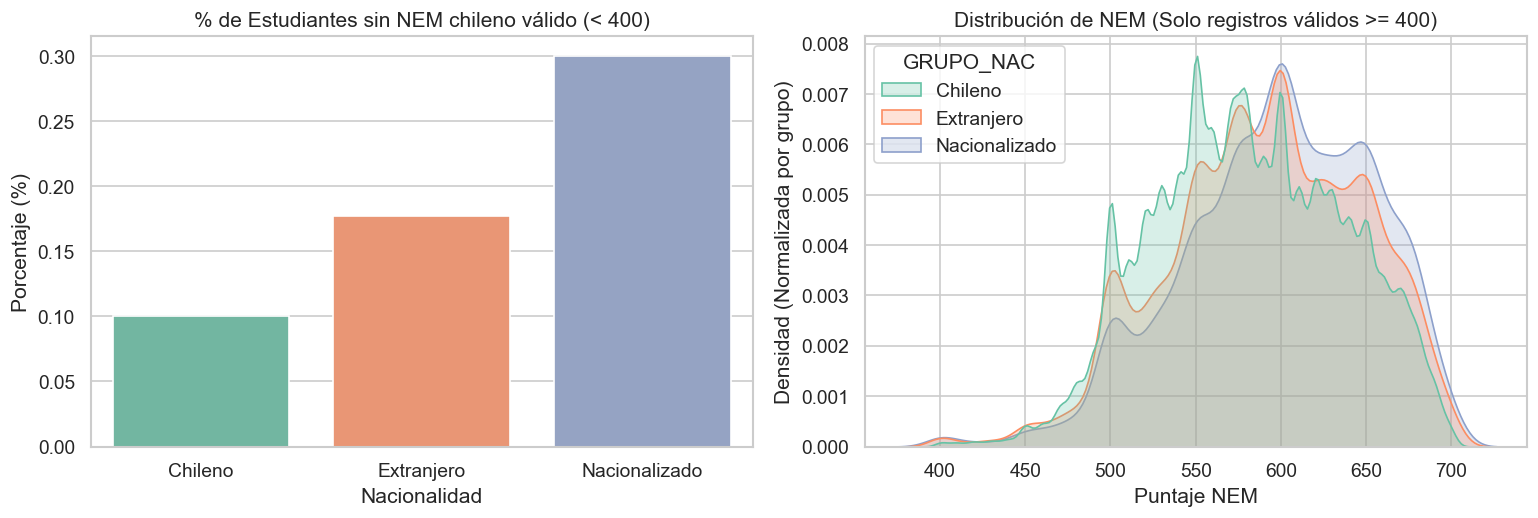

In [48]:
# Configuración visual limpia para portafolio
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

# Cargar el dataset maestro
df = pd.read_parquet("../datasets/processed/dataset_maestro_permanencia.parquet")

# Mapear etiquetas legibles para los gráficos
mapa_nac = {0: "Chileno", 1: "Extranjero", 2: "Nacionalizado"}
df["GRUPO_NAC"] = df["NACIONALIDAD"].map(mapa_nac)

# --- GRÁFICO 1: Auditoría de NEM (Detectando los sin registro < 400) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# 1A: Proporción de estudiantes con NEM < 400 (sin NEM válido en Chile)
sin_nem = df.groupby("GRUPO_NAC")["NEM"].apply(lambda s: (s < 400).mean() * 100).reset_index()
sns.barplot(data=sin_nem, x="GRUPO_NAC", y="NEM", ax=axes[0], palette="Set2")
axes[0].set_title("% de Estudiantes sin NEM chileno válido (< 400)")
axes[0].set_ylabel("Porcentaje (%)")
axes[0].set_xlabel("Nacionalidad")

# 1B: Distribución de densidad (KDE) solo para quienes tienen NEM válido (>= 400)
sns.kdeplot(
    data=df[df["NEM"] >= 400], x="NEM", hue="GRUPO_NAC", 
    common_norm=False, fill=True, alpha=0.25, ax=axes[1], palette="Set2"
)
axes[1].set_title("Distribución de NEM (Solo registros válidos >= 400)")
axes[1].set_xlabel("Puntaje NEM")
axes[1].set_ylabel("Densidad (Normalizada por grupo)")

plt.tight_layout()
plt.show()

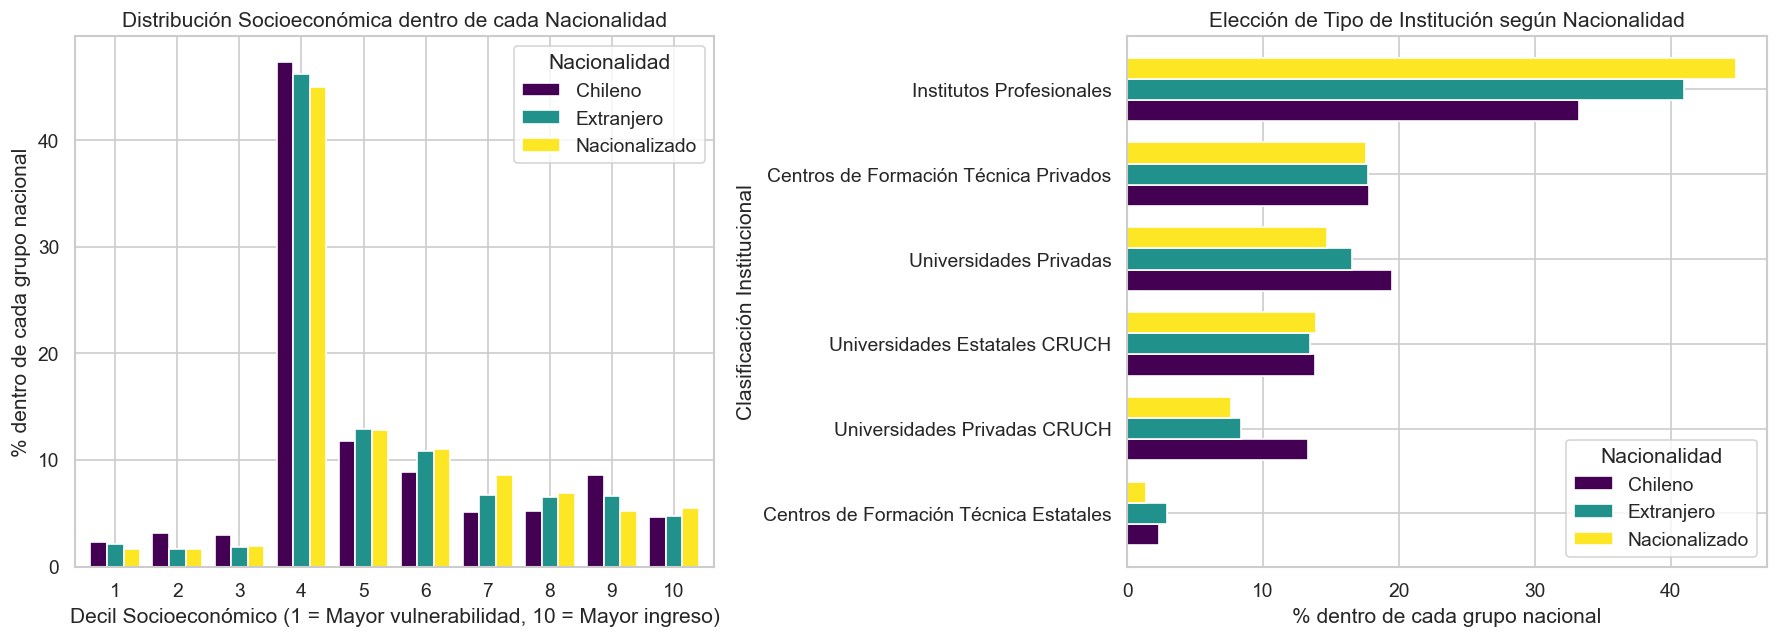

In [49]:
# --- GRÁFICO 2: Distribución por Decil Socioeconómico y Tipo de Institución ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 2A: Tabla cruzada normalizada por nacionalidad para DECIL_SE4
# Filtramos deciles válidos del 1 al 10
df_decil = df[df["DECIL_SE4"].between(1, 10)]
tab_decil = pd.crosstab(
    df_decil["DECIL_SE4"].astype(int), 
    df_decil["GRUPO_NAC"], 
    normalize="columns"
) * 100

tab_decil.plot(kind="bar", ax=axes[0], width=0.8, colormap="viridis")
axes[0].set_title("Distribución Socioeconómica dentro de cada Nacionalidad")
axes[0].set_xlabel("Decil Socioeconómico (1 = Mayor vulnerabilidad, 10 = Mayor ingreso)")
axes[0].set_ylabel("% dentro de cada grupo nacional")
axes[0].legend(title="Nacionalidad")
axes[0].tick_params(axis="x", rotation=0)

# 2B: Distribución por Tipo de Institución (TIPO_INST_3)
tab_inst = pd.crosstab(
    df["TIPO_INST_3"], 
    df["GRUPO_NAC"], 
    normalize="columns"
) * 100

# Ordenar de mayor a menor presencia en extranjeros para facilitar la lectura
tab_inst = tab_inst.sort_values(by="Extranjero", ascending=True)
tab_inst.plot(kind="barh", ax=axes[1], width=0.75, colormap="viridis")
axes[1].set_title("Elección de Tipo de Institución según Nacionalidad")
axes[1].set_xlabel("% dentro de cada grupo nacional")
axes[1].set_ylabel("Clasificación Institucional")
axes[1].legend(title="Nacionalidad")

plt.tight_layout()
plt.show()

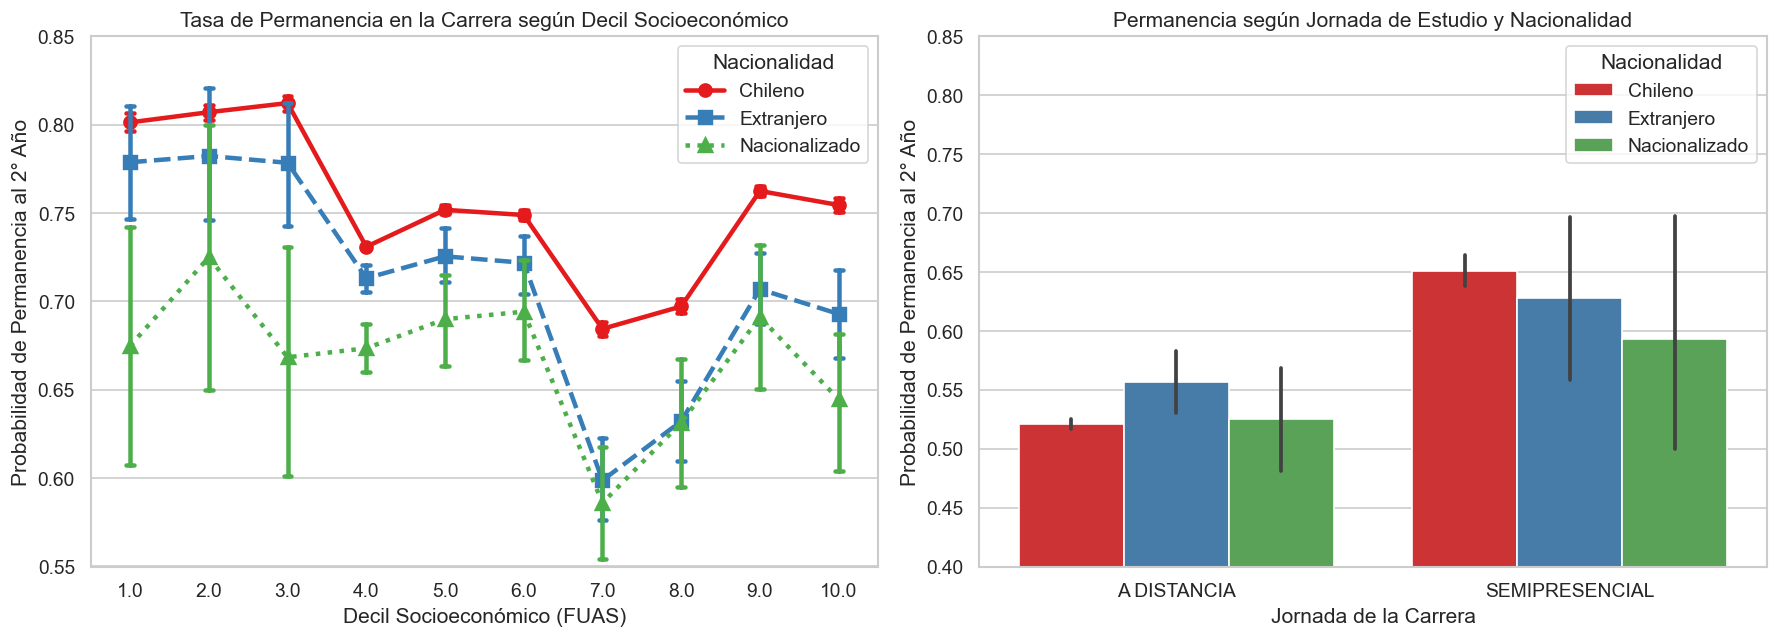

In [50]:
# --- GRÁFICO 3: Curvas de Permanencia por Decil y por Jornada ---
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 3A: Tasa de permanencia a lo largo de los 10 deciles socioeconómicos
sns.pointplot(
    data=df_decil, 
    x="DECIL_SE4", 
    y="PERMANECE_CARRERA", 
    hue="GRUPO_NAC",
    errorbar=("ci", 95),
    capsize=0.1,
    markers=["o", "s", "^"],
    linestyles=["-", "--", ":"],
    ax=axes[0],
    palette="Set1"
)
axes[0].set_title("Tasa de Permanencia en la Carrera según Decil Socioeconómico")
axes[0].set_xlabel("Decil Socioeconómico (FUAS)")
axes[0].set_ylabel("Probabilidad de Permanencia al 2° Año")
axes[0].set_ylim(0.55, 0.85)  # Ajustar eje Y para apreciar la brecha con claridad
axes[0].legend(title="Nacionalidad")

# 3B: Permanencia según Jornada (Diurno vs Vespertino vs A Distancia)
jornadas_principales = ["DIURNO", "VESPERTINO", "A DISTANCIA", "SEMIPRESENCIAL"]
df_jor = df[df["JORNADA"].str.upper().str.strip().isin(jornadas_principales)].copy()
df_jor["JORNADA_LIMPIA"] = df_jor["JORNADA"].str.upper().str.strip()

sns.barplot(
    data=df_jor,
    x="JORNADA_LIMPIA",
    y="PERMANECE_CARRERA",
    hue="GRUPO_NAC",
    errorbar=("ci", 95),
    ax=axes[1],
    palette="Set1"
)
axes[1].set_title("Permanencia según Jornada de Estudio y Nacionalidad")
axes[1].set_xlabel("Jornada de la Carrera")
axes[1].set_ylabel("Probabilidad de Permanencia al 2° Año")
axes[1].set_ylim(0.40, 0.85)
axes[1].legend(title="Nacionalidad")

plt.tight_layout()
plt.show()

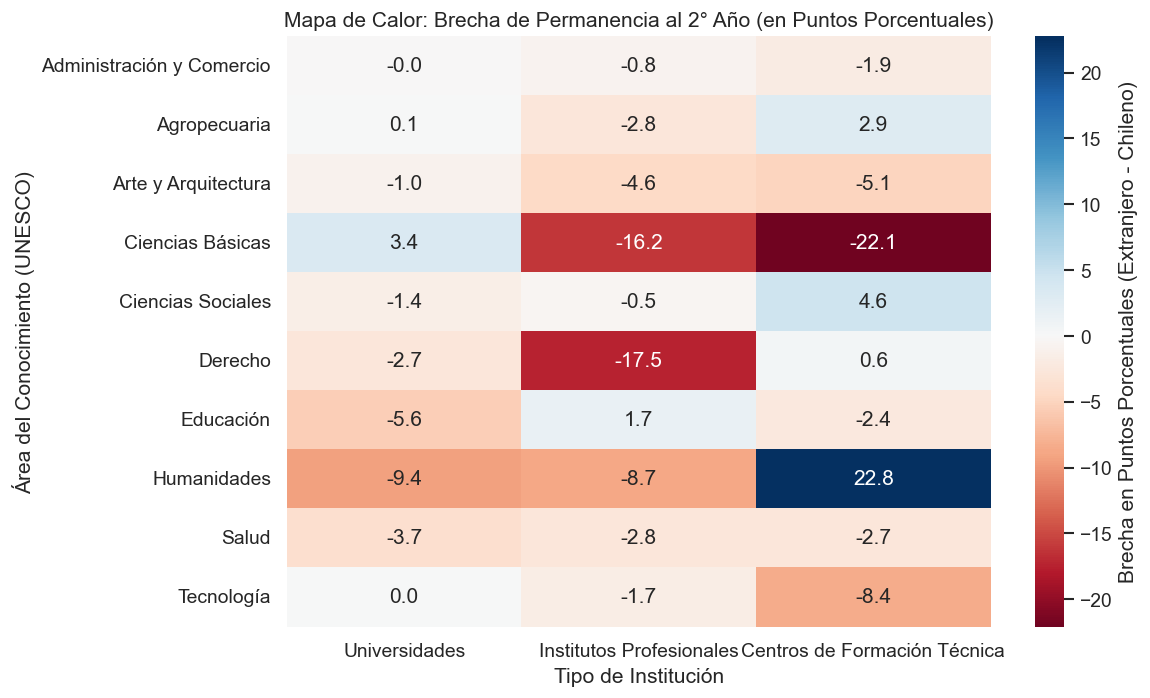

In [51]:
# --- GRÁFICO 4: Heatmap de Brecha de Permanencia (Extranjeros vs Chilenos) ---
# Filtramos solo Chilenos (0) y Extranjeros (1) para medir la brecha directa
df_bin = df[df["NACIONALIDAD"].isin([0, 1])].copy()

# Calcular tasa de permanencia por Área, Institución y Nacionalidad
pivote = df_bin.pivot_table(
    index="AREA_CONOCIMIENTO",
    columns=["TIPO_INST_1", "ES_EXTRANJERO"],
    values="PERMANECE_CARRERA",
    aggfunc="mean"
)

# Calcular la diferencia en puntos porcentuales: (Tasa Extranjero - Tasa Chileno) * 100
brecha_matriz = pd.DataFrame(index=pivote.index)
for inst in df_bin["TIPO_INST_1"].unique():
    if (inst, 1) in pivote.columns and (inst, 0) in pivote.columns:
        brecha_matriz[inst] = (pivote[(inst, 1)] - pivote[(inst, 0)]) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(
    brecha_matriz, 
    annot=True, 
    fmt=".1f", 
    cmap="RdBu", 
    center=0, 
    cbar_kws={"label": "Brecha en Puntos Porcentuales (Extranjero - Chileno)"}
)
plt.title("Mapa de Calor: Brecha de Permanencia al 2° Año (en Puntos Porcentuales)")
plt.xlabel("Tipo de Institución")
plt.ylabel("Área del Conocimiento (UNESCO)")
plt.tight_layout()
plt.show()

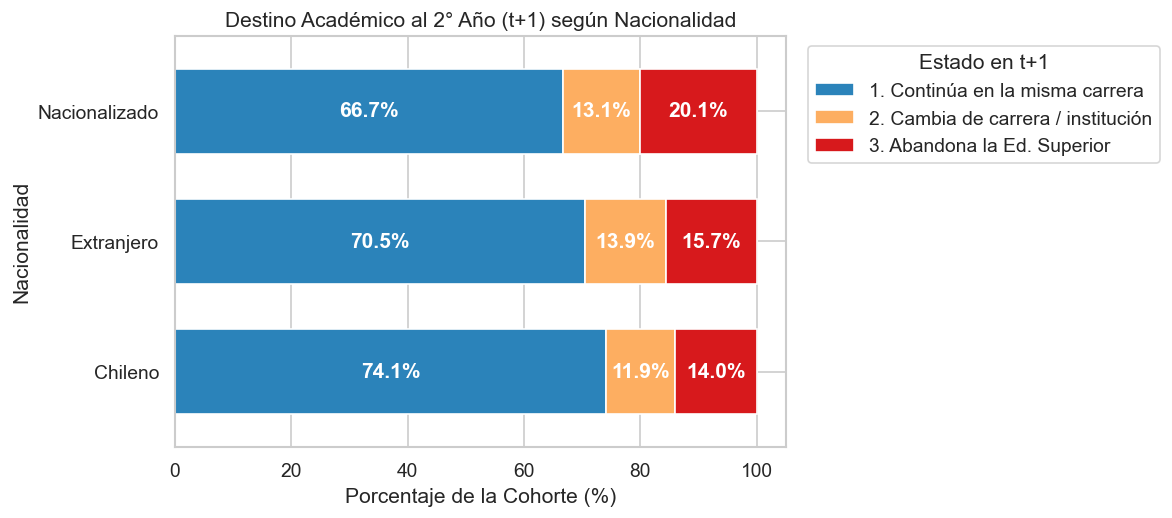

In [52]:
# --- GRÁFICO 5: Descomposición del Destino al Año t+1 ---
condiciones = [
    df["PERMANECE_CARRERA"] == 1,
    (df["PERMANECE_CARRERA"] == 0) & (df["PERMANECE_SISTEMA"] == 1),
    df["PERMANECE_SISTEMA"] == 0
]
opciones = [
    "1. Continúa en la misma carrera", 
    "2. Cambia de carrera / institución", 
    "3. Abandona la Ed. Superior"
]
df["DESTINO_T1"] = np.select(condiciones, opciones, default="Otro")

tab_destino = pd.crosstab(df["GRUPO_NAC"], df["DESTINO_T1"], normalize="index") * 100

ax = tab_destino.plot(
    kind="barh", stacked=True, figsize=(10, 4.5), 
    color=["#2b83ba", "#fdae61", "#d7191c"], width=0.65
)
plt.title("Destino Académico al 2° Año (t+1) según Nacionalidad")
plt.xlabel("Porcentaje de la Cohorte (%)")
plt.ylabel("Nacionalidad")
plt.legend(title="Estado en t+1", bbox_to_anchor=(1.02, 1), loc="upper left")

# Agregar etiquetas de porcentaje dentro de cada segmento de barra
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", label_type="center", color="white", fontweight="bold")

plt.tight_layout()
plt.show()

In [53]:
df.columns.to_list()

['CAT_PERIODO',
 'CODIGO_UNICO',
 'MRUN',
 'GEN_ALU',
 'TIPO_INST_1',
 'TIPO_INST_3',
 'MODALIDAD',
 'JORNADA',
 'DUR_TOTAL_CARR',
 'REGION_SEDE',
 'FORMATO_VALORES',
 'VALOR_MATRICULA',
 'VALOR_ARANCEL',
 'AREA_CONOCIMIENTO',
 'ACREDITADA_INST',
 'ACRE_INST_ANIO',
 'EDAD',
 'DECIL_SE4',
 'COD_DEPE',
 'NEM',
 'NACIONALIDAD',
 'ETNIA',
 'PERMANECE_CARRERA',
 'PERMANECE_SISTEMA',
 'ES_EXTRANJERO',
 'ANIO_COHORTE',
 'GRUPO_NAC',
 'DESTINO_T1']

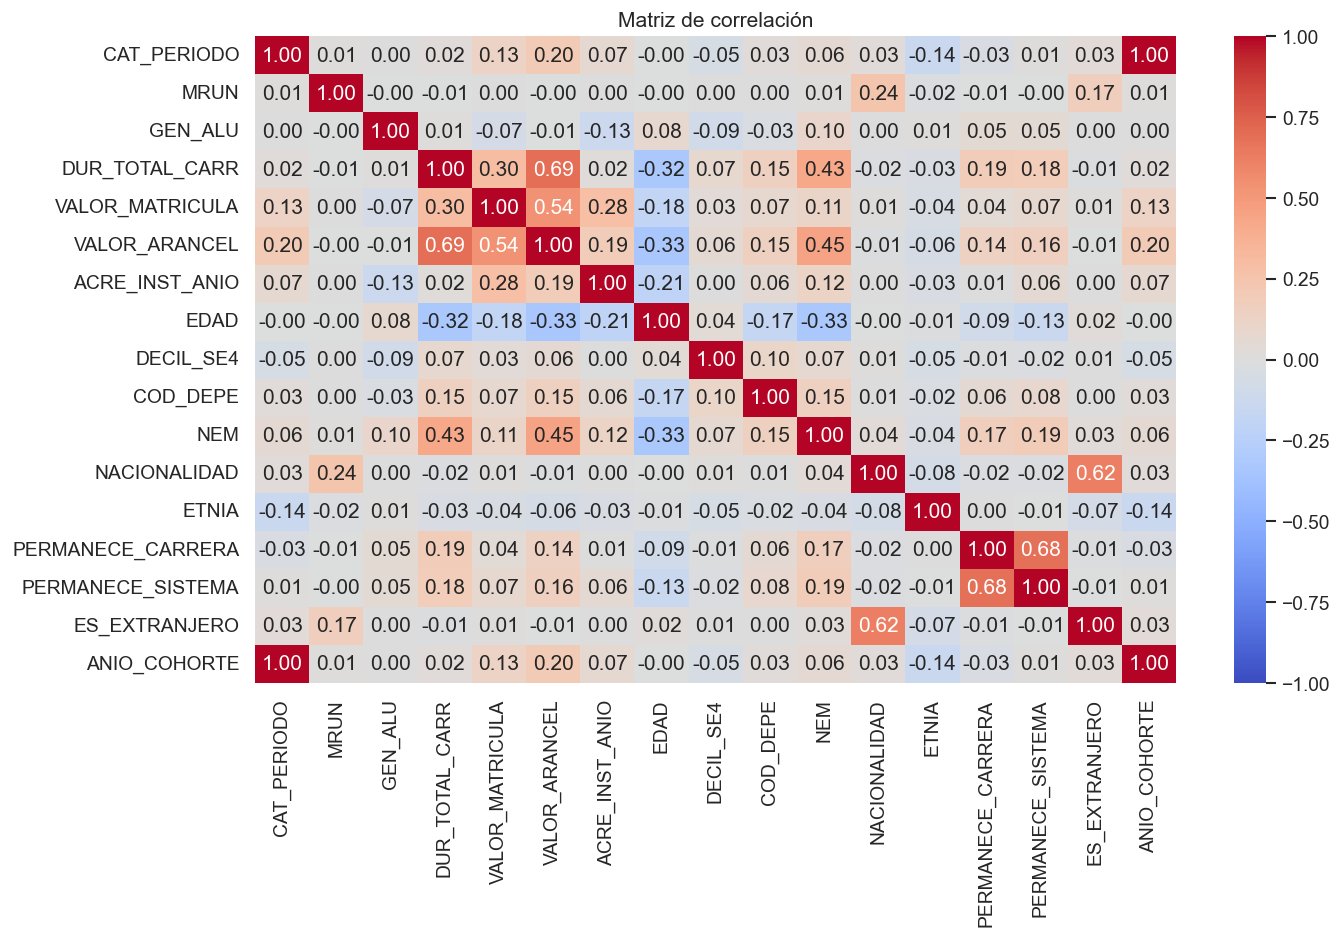

In [54]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    vmin=-1,
    vmax=1,
    center=0
)
plt.title('Matriz de correlación')
plt.tight_layout()
plt.show()

In [55]:
# Auditoría rápida de las variables numéricas restantes para el clustering
print("--- FORMATO DE VALORES DEL ARANCEL ---")
if "FORMATO_VALORES" in df.columns:
    print(df["FORMATO_VALORES"].value_counts(dropna=False))

print("\n--- ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES NUMÉRICAS CLAVE ---")
cols_auditar = ["NEM", "EDAD", "DECIL_SE4", "DUR_TOTAL_CARR", "VALOR_ARANCEL", "ACRE_INST_ANIO"]
display(df[cols_auditar].describe().round(2))

print("\n--- DISTRIBUCIÓN DE DEPENDENCIA ESCOLAR (COD_DEPE) ---")
print(df["COD_DEPE"].value_counts(dropna=False).sort_index())

--- FORMATO DE VALORES DEL ARANCEL ---
FORMATO_VALORES
Monto en Pesos    1049523
Monto en UF         14431
Name: count, dtype: int64

--- ESTADÍSTICAS DESCRIPTIVAS DE VARIABLES NUMÉRICAS CLAVE ---


,NEM,EDAD,DECIL_SE4,DUR_TOTAL_CARR,VALOR_ARANCEL,ACRE_INST_ANIO
count,1063834.00,1063954.00,1061867.00,1063954.00,1063954.00,1063954.00
mean,580.60,22.51,5.21,7.61,3476911.45,5.38
std,56.23,7.05,2.12,2.54,1687292.45,1.46
min,0.00,10.00,1.00,3.00,0.00,0.00
25%,540.00,18.00,4.00,5.00,2237000.00,5.00
50%,580.00,19.00,4.00,8.00,2900000.00,5.00
75%,623.00,23.00,6.00,10.00,4608000.00,7.00
max,700.00,124.00,10.00,14.00,11180000.00,7.00



--- DISTRIBUCIÓN DE DEPENDENCIA ESCOLAR (COD_DEPE) ---
COD_DEPE
1.0    224703
2.0    222245
3.0    503509
4.0     59621
5.0     25830
6.0     27899
NaN       147
Name: count, dtype: int64


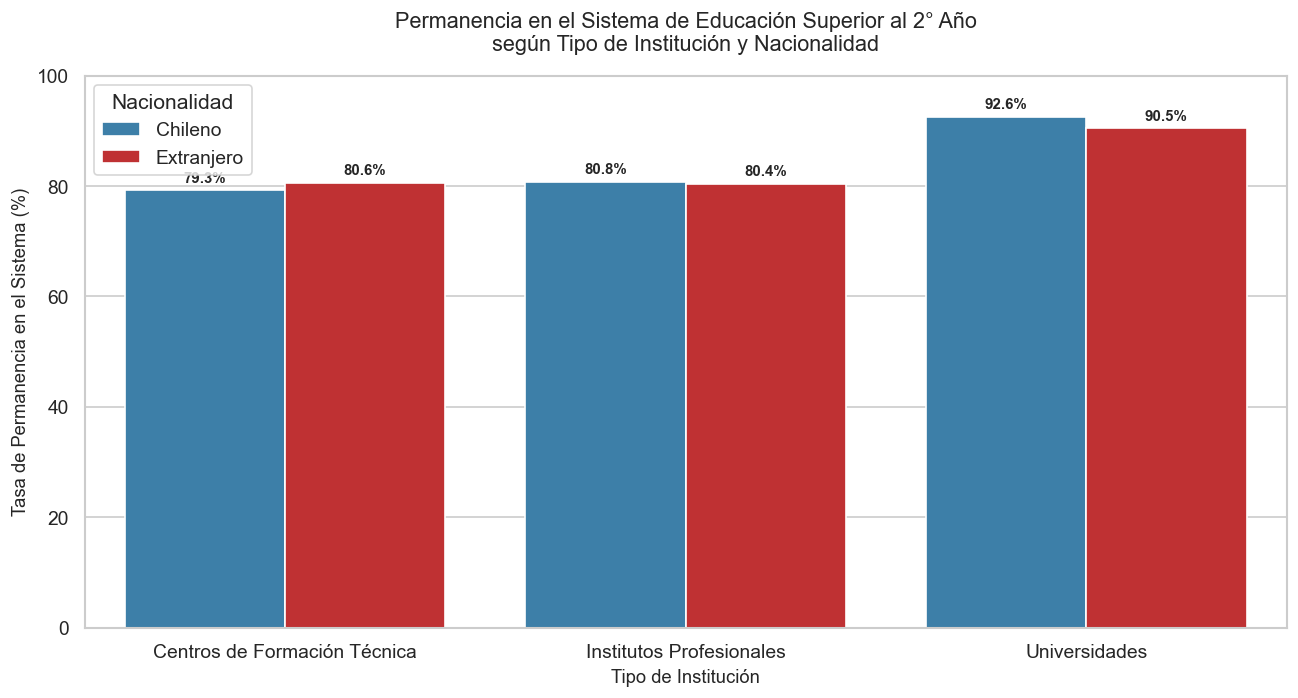

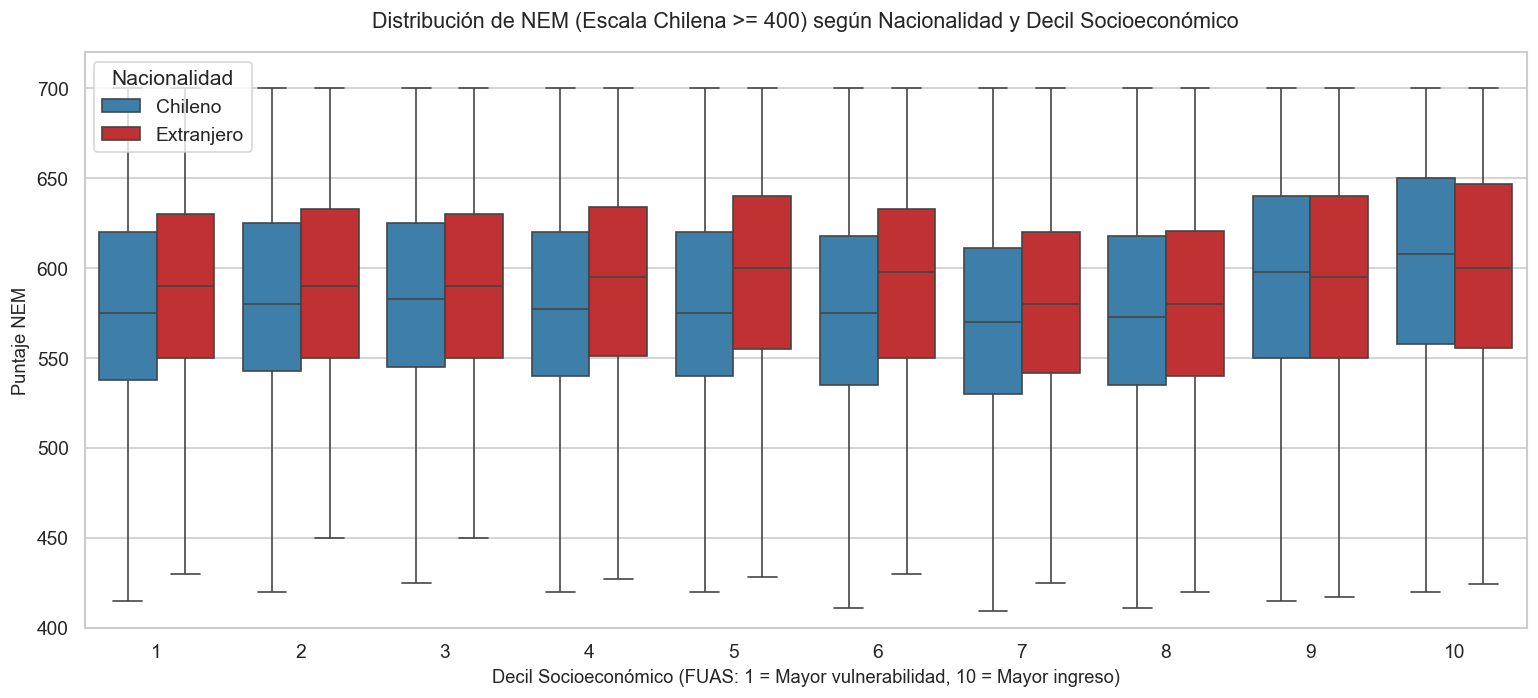

In [ ]:
# ============================================================
# CEDA: GRÁFICOS DE PERMANENCIA EN EL SISTEMA Y DISTRIBUCIÓN NEM
# Métrica de éxito: PERMANECE_SISTEMA (continúa en la misma u otra institución)
# ============================================================

# 1. Preparar muestra de análisis (Chilenos vs Extranjeros) sobre los datos limpios
# Si ya ejecutaste la celda de limpieza usa df_clean, de lo contrario usa df
base_plot = df_clean.copy() if 'df_clean' in locals() else df.copy()

# Filtrar chilenos (0) y extranjeros (1)
mapa_nac = {0: "Chileno", 1: "Extranjero"}
analisis_plot = base_plot[base_plot["NACIONALIDAD"].isin([0, 1])].copy()
analisis_plot["GRUPO_NAC"] = analisis_plot["NACIONALIDAD"].map(mapa_nac)

# Homologar nombre de columna de tipo de institución si aplica
col_inst = "TIPO_INST_1" if "TIPO_INST_1" in analisis_plot.columns else "TIPO_INST_3"

# ------------------------------------------------------------
# FUNCIÓN DE INTERVALOS DE CONFIANZA DE WILSON (95%)
# ------------------------------------------------------------
def intervalo_wilson(exitos, n, z=1.96):
    if n == 0:
        return np.nan, np.nan
    p = exitos / n
    denominador = 1 + (z**2) / n
    centro = (p + (z**2) / (2 * n)) / denominador
    margen = (z * math.sqrt((p * (1 - p) / n) + (z**2) / (4 * n**2))) / denominador
    return centro - margen, centro + margen

# ============================================================
# GRÁFICO 1: PERMANENCIA EN EL SISTEMA SEGÚN INSTITUCIÓN Y NACIONALIDAD
# ============================================================
resumen_perm = (
    analisis_plot
    .groupby([col_inst, "GRUPO_NAC"], observed=True)
    .agg(
        n=("PERMANECE_SISTEMA", "size"),
        permanecen=("PERMANECE_SISTEMA", "sum")
    )
    .reset_index()
)

resumen_perm["tasa"] = resumen_perm["permanecen"] / resumen_perm["n"]

# Calcular intervalos de Wilson
ic_valores = resumen_perm.apply(
    lambda f: intervalo_wilson(f["permanecen"], f["n"]), axis=1
)
resumen_perm["IC95_INF"] = [x[0] for x in ic_valores]
resumen_perm["IC95_SUP"] = [x[1] for x in ic_valores]

# Convertir a porcentaje
resumen_perm["tasa_pct"] = resumen_perm["tasa"] * 100
resumen_perm["IC95_INF_pct"] = resumen_perm["IC95_INF"] * 100
resumen_perm["IC95_SUP_pct"] = resumen_perm["IC95_SUP"] * 100

orden_nac = ["Chileno", "Extranjero"]

fig, ax1 = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=resumen_perm,
    x=col_inst,
    y="tasa_pct",
    hue="GRUPO_NAC",
    hue_order=orden_nac,
    palette=["#2b83ba", "#d7191c"],
    errorbar=None,
    ax=ax1
)

ax1.set_title(
    "Permanencia en el Sistema de Educación Superior al 2° Año\nsegún Tipo de Institución y Nacionalidad",
    fontsize=13,
    pad=15
)
ax1.set_xlabel("Tipo de Institución", fontsize=11)
ax1.set_ylabel("Tasa de Permanencia en el Sistema (%)", fontsize=11)
ax1.set_ylim(0, 100)
ax1.legend(title="Nacionalidad")

# Etiquetas de porcentaje sobre cada barra
for container in ax1.containers:
    ax1.bar_label(container, fmt="%.1f%%", padding=3, fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 2: DISTRIBUCIÓN DE NEM SEGÚN NACIONALIDAD Y DECIL
# ============================================================
# Filtrar registros válidos: deciles 1 a 10 y NEM escolar chileno (>= 400)
df_nem_decil = analisis_plot[
    analisis_plot["DECIL_SE4"].between(1, 10) & 
    (analisis_plot["NEM"] >= 400)
].copy()

df_nem_decil["DECIL_SE4"] = df_nem_decil["DECIL_SE4"].astype(int)

fig, ax2 = plt.subplots(figsize=(13, 6))

sns.boxplot(
    data=df_nem_decil,
    x="DECIL_SE4",
    y="NEM",
    hue="GRUPO_NAC",
    hue_order=orden_nac,
    palette=["#2b83ba", "#d7191c"],
    showfliers=False,  # Oculta puntos aislados extremos para apreciar bien la caja y mediana
    ax=ax2
)

ax2.set_title(
    "Distribución de NEM (Escala Chilena >= 400) según Nacionalidad y Decil Socioeconómico",
    fontsize=13,
    pad=15
)
ax2.set_xlabel("Decil Socioeconómico (FUAS: 1 = Mayor vulnerabilidad, 10 = Mayor ingreso)", fontsize=11)
ax2.set_ylabel("Puntaje NEM", fontsize=11)
ax2.set_ylim(400, 720)
ax2.legend(title="Nacionalidad", loc="upper left")

plt.tight_layout()
plt.show()